# Analysis Human-Team (Phase II)

### Load and import

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import GeoCLIPModel, PredictionRunner, Segmenter

from pair_a.q2_confidence import usable
from pair_a import q2_confidence_phase2 as q2p

cfg = Config()
mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)

out_dir = Path("results/pair_a/phase2")
(out_dir / "q2").mkdir(parents=True, exist_ok=True)
print(f"{len(preds):,} predictions | model: {info['model']}")

/home/mut/projects/AI4VIS/ai_and_visualisation_OpenSI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


210,122 predictions | model: geolocal/StreetCLIP


# Q1: Error structure and geography

# Q2: Overconfidence and training coverage

### Q2.1 Where do confident errors lie in the embedding space?
- kNN in StreetCLIP's image embeddings (k = 10, cosine similarity)
- Neighbours from the same camera sequence or closer than 50 km are skipped, otherwise kNN finds the same place
- References: at most 300 images per country, so big countries do not win the vote by size
- Queries: at most 50 images per country and group (correct / wrong x confident / unsure)

,n,countries,share_true,share_pred,vote_true,vote_pred,vote_pred_low,vote_pred_high
group,,,,,,,,
correct / confident,3239,114,0.700,0.700,0.840,0.840,0.827,0.853
correct / unsure,6896,183,0.430,0.430,0.556,0.556,0.545,0.568
wrong / confident,1607,122,0.308,0.360,0.354,0.448,0.424,0.472
wrong / unsure,8283,188,0.266,0.115,0.340,0.136,0.128,0.143


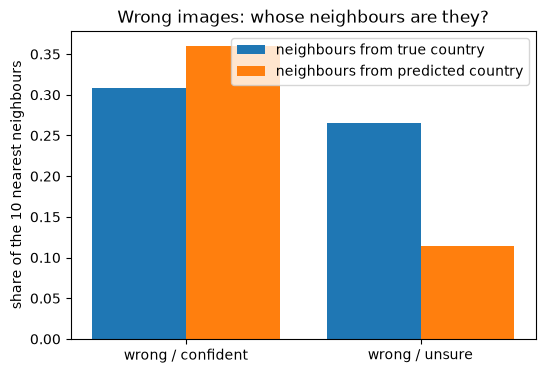

In [2]:
emb = q2p.load_embeddings(f"results/shared/{run_name}")
p = q2p.add_group(usable(preds))
ref = p.sample(frac=1, random_state=1).groupby("country_id").head(300)

q21 = p.sample(frac=1, random_state=42).groupby(["country_id", "group"]).head(50)
q21 = q2p.knn_columns(q21, q2p.neighbours(emb, ref, q21, min_km=50))
t21 = q2p.group_table(q21)
display(t21.round(3))
q2p.plot_groups(t21)

### Q2.2 Training coverage: CLIP vs. StreetCLIP embeddings
- Same kNN for both models, same queries (at most 100 per country) and references
- kNN accuracy: share of images whose neighbour vote is the true country
- If fine-tuning taught the list countries, their kNN accuracy should grow more from CLIP to StreetCLIP

countries: 86 on the list, 85 not on the list


,on_list_mean,off_list_mean,on_list_median,off_list_median,p_value
value,,,,,
knn_street,0.509,0.354,0.535,0.40,0.000
knn_clip,0.497,0.358,0.495,0.39,0.001
knn_gain,0.012,-0.004,0.010,0.00,0.056
zeroshot_gain,0.032,0.017,0.030,0.02,0.974


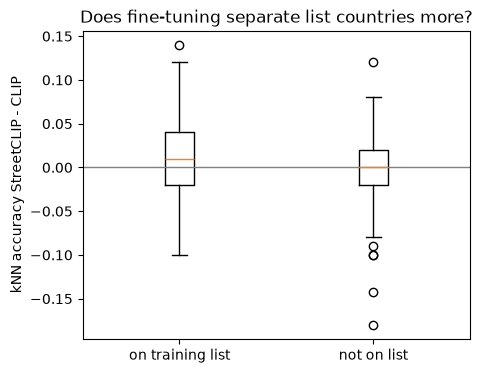

,n,zeroshot_street,zeroshot_clip,knn_street,knn_clip,knn_gain,zeroshot_gain,on_list,low_n
country_id,,,,,,,,,
GE,100,0.00,0.02,0.29,0.27,0.02,-0.02,False,False
CD,100,0.00,0.02,0.48,0.52,-0.04,-0.02,False,False
LT,100,0.02,0.06,0.24,0.25,-0.01,-0.04,True,False


In [3]:
preds_clip, _, _, _ = PredictionRunner.load("results/shared/clip_v1_center_crop")
emb_clip = q2p.load_embeddings("results/shared/clip_v1_center_crop")
p_clip = usable(preds_clip)

q22 = p.sample(frac=1, random_state=42).groupby("country_id").head(100)
q_street = q2p.knn_columns(q22, q2p.neighbours(emb, ref, q22, min_km=50))
q_clip = q2p.knn_columns(p_clip.loc[q22.index],
                         q2p.neighbours(emb_clip, p_clip.loc[ref.index], p_clip.loc[q22.index], min_km=50))
t22 = q2p.country_table(q_street, q_clip, mapper)
display(q2p.compare_lists(t22).round(3))
q2p.plot_gain(t22)
display(t22.loc[["GE", "CD", "LT"]].round(2))

### Q2.3 Grad-CAM: confident errors vs. confident correct
- US images with confidence >= 0.8: guessed as Canada (all 455) vs. guessed correctly (455 drawn at random)
- Grad-CAM for the predicted country, last vision layer
- Share of the heat on each element (Mask2Former segments, same elements as Q3)


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 590/590 [00:00<00:00, 12927.06it/s]


Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]


Loading weights:  35%|███▌      | 268/758 [00:00<00:00, 2634.87it/s]


Loading weights:  70%|███████   | 532/758 [00:00<00:00, 2021.11it/s]


Loading weights: 100%|██████████| 758/758 [00:00<00:00, 2436.72it/s]


[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing fro

,heat_wrong,heat_correct,area_wrong,area_correct,p_value
element,,,,,
road,0.318,0.373,0.251,0.252,0.000
vegetation,0.350,0.262,0.235,0.221,0.000
sky,0.226,0.294,0.369,0.435,0.000
buildings,0.027,0.011,0.020,0.007,0.000
vehicles,0.006,0.006,0.005,0.006,0.000
signs_poles,0.010,0.008,0.004,0.006,0.876


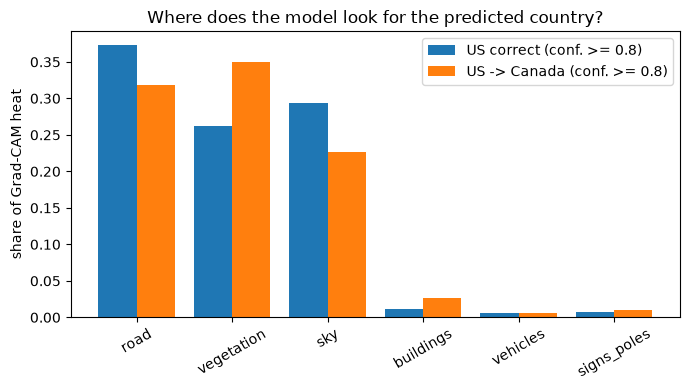

In [4]:
heat_file = out_dir / "q2" / "gradcam_us_canada.parquet"

us = p[(p["country_id"] == "US") & (p["prob_1"] >= 0.8)]
wrong = us[us["pred_1"] == "CA"].assign(group="US -> Canada")
right = us[us["pred_1"] == "US"].sample(len(wrong), random_state=42).assign(group="US correct")
rows = pd.concat([wrong, right])

if heat_file.exists():
    heat = pd.read_parquet(heat_file)
else:
    cfg.half_precision = False
    geo = GeoCLIPModel(cfg.streetclip_model, cfg)
    geo.set_candidates(info["labels"], mapper.prompts(info["labels"], cfg.prompt_template))
    cam = q2p.make_cam(geo)
    segmenter = Segmenter(cfg)
    heat = q2p.heat_per_element(cam, geo, segmenter, dataset, rows, cfg.crop_mode)
    heat = heat.merge(rows[["id", "group", "sequence"]], on="id")
    heat.to_parquet(heat_file)

t23 = q2p.element_table(heat, list(cfg.element_classes))
display(t23.round(3))
q2p.plot_elements(t23)

### Q2 findings

# Q3: Visual clues

# Q4: Environment

### Q4.1 Built-up vs. rural in the embedding space

### Q4.2 Climate and land cover in the embedding space

### Q4.3 Grad-CAM: built-up vs. rural

### Q4 findings